# 03 — Des heures prévues aux effectifs

Le notebook 02 prévoit des **heures de travail**. Un responsable de site raisonne en **personnes** :
combien d'archivistes me faut-il en mars ? Dois-je prévoir un intérimaire ? Puis-je accorder ces congés ?

Ce notebook fait la traduction et répond à trois questions :

1. **Les alertes** : si on avait suivi la prévision en 2026, aurait-on vu venir les semaines de surcharge ?
2. **Le pilotage** : combien d'heures de surcharge et d'heures inutilisées aurait-on évitées par rapport à
   la règle actuelle (effectif = charge moyenne de l'an dernier) ?
3. **Le plan** : de quoi chaque site aura-t-il besoin de novembre 2026 à janvier 2027 ?

**Vocabulaire :**
- **ETP** (équivalent temps plein) : 1 ETP = une personne à temps plein, 7 h par jour ouvré.
- **Capacité d'un ETP** : les heures qu'une personne fournit réellement, une fois retirés congés et absences.
  Hypothèse du générateur : 92 % de présence en temps normal, 82 % en juillet et décembre, 62 % en août.
- **Taux de charge cible** : on ne remplit pas une équipe à 100 %. On vise **90 %**, pour absorber les
  imprévus (un audit client, une absence) et garder du temps pour les inventaires et la formation.

In [1]:
from pathlib import Path
import logging, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import holidays
from prophet import Prophet

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").disabled = True
logging.getLogger("prophet").setLevel(logging.ERROR)

DATA = Path("data") if Path("data").exists() else Path("../data")
OUT = DATA.parent / "outputs"
plt.rcParams.update({"figure.figsize": (13, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

HEURES_JOUR = 7.0
TAUX_CIBLE = 0.90
def presence(mois):                     # part du temps réellement présent (congés, absences)
    return np.where(mois == 8, 0.62, np.where(np.isin(mois, [7, 12]), 0.82, 0.92))

prev     = pd.read_csv(OUT / "previsions_2026.csv", parse_dates=["date"])     # produit par 02_prophet
charge   = pd.read_csv(DATA / "fact_charge_jour.csv", parse_dates=["date"])
dim_site = pd.read_csv(DATA / "dim_site.csv")
NOMS = dim_site.set_index("site_id").ville.to_dict()
SITES = sorted(prev.site_id.unique())

d = prev.merge(charge[["date", "site_id", "etp_archivistes", "heures_disponibles"]], on=["date", "site_id"])
d["capacite_1_etp"] = HEURES_JOUR * presence(d.date.dt.month)
d[["date", "site_id", "heures_reelles", "prev_modele_retenu", "etp_archivistes", "capacite_1_etp"]].head()

,date,site_id,heures_reelles,prev_modele_retenu,etp_archivistes,capacite_1_etp
0,2026-01-02,S01,25.26,25.72,9.0,6.44
1,2026-01-05,S01,60.57,62.58,9.0,6.44
2,2026-01-06,S01,63.58,60.72,9.0,6.44
3,2026-01-07,S01,46.04,59.06,9.0,6.44
4,2026-01-08,S01,44.35,59.68,9.0,6.44


## 1. Combien d'archivistes chaque semaine ?

La formule :

> **ETP nécessaires = heures prévues ÷ (capacité d'un ETP × 90 %)**

Exemple : une semaine de 5 jours en mars avec 180 h prévues. Un ETP fournit 5 × 7 × 0,92 = 32,2 h.
Il faut donc 180 ÷ (32,2 × 0,9) ≈ **6,2 ETP**.

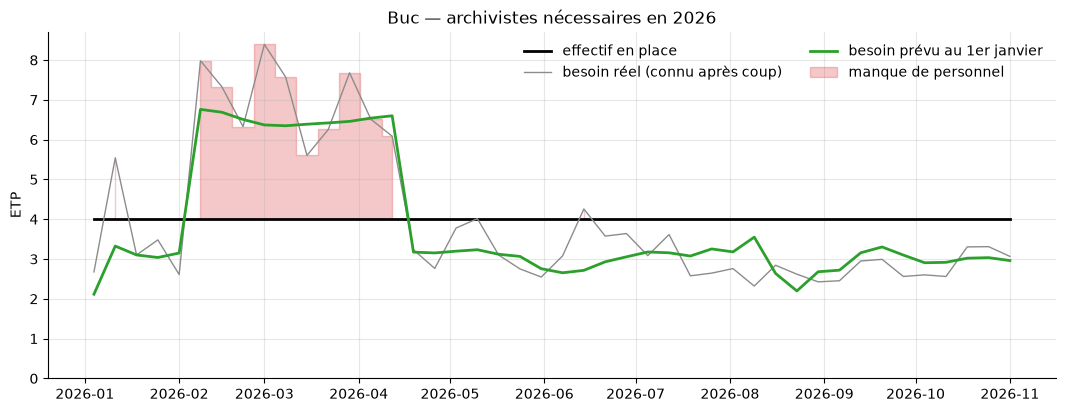

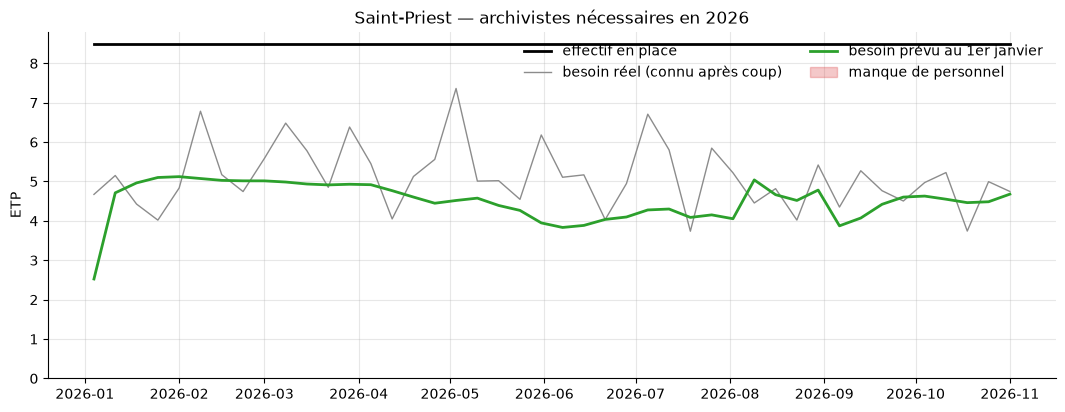

In [2]:
sem = (d.groupby(["site_id", pd.Grouper(key="date", freq="W-SUN")])
        .agg(heures_reelles=("heures_reelles", "sum"), heures_prevues=("prev_modele_retenu", "sum"),
             borne_haute=("prev_borne_haute", "sum"), capacite_1_etp=("capacite_1_etp", "sum"),
             etp_en_place=("etp_archivistes", "first"), heures_dispo=("heures_disponibles", "sum"))
        .reset_index())
sem = sem[sem.heures_dispo > 0]
sem["etp_necessaires_prevus"] = sem.heures_prevues / (sem.capacite_1_etp * TAUX_CIBLE)
sem["etp_necessaires_reels"]  = sem.heures_reelles / (sem.capacite_1_etp * TAUX_CIBLE)

def tracer(site):
    s = sem[sem.site_id == site].set_index("date")
    fig, ax = plt.subplots()
    ax.step(s.index, s.etp_en_place, where="mid", color="k", lw=2, label="effectif en place")
    ax.plot(s.etp_necessaires_reels, color="0.55", lw=1, label="besoin réel (connu après coup)")
    ax.plot(s.etp_necessaires_prevus, color="C2", lw=2, label="besoin prévu au 1er janvier")
    ax.fill_between(s.index, s.etp_en_place, s.etp_necessaires_reels,
                    where=s.etp_necessaires_reels > s.etp_en_place, color="C3", alpha=0.25, step="mid",
                    label="manque de personnel")
    ax.set(title=f"{NOMS[site]} — archivistes nécessaires en 2026", ylabel="ETP", xlabel="", ylim=(0, None))
    ax.legend(frameon=False, ncol=2, loc="upper right"); plt.show()

for site in ["S02", "S05"]:
    tracer(site)

**Comment lire :**
- **Ligne noire** : le nombre d'archivistes réellement en poste, fixé en début d'année.
- **Gris** : le besoin réel, qu'on ne connaît qu'une fois l'année passée.
- **Vert** : le besoin que la prévision annonçait dès le 1er janvier.
- **Zone rouge** : les semaines où l'équipe était trop petite.

À **Buc**, l'effectif a été fixé sur la charge de 2025 sans tenir compte de la reprise de février-avril
2026, pourtant signée à l'avance : l'équipe est débordée pendant deux mois. La prévision, elle, annonçait
le besoin.
À **Saint-Priest**, c'est l'inverse : l'effectif a été gonflé à cause de la reprise de 2025, qui ne s'est
pas répétée. Toute l'année, le site a environ 3 à 4 ETP de trop.

**Mes observations :**
<!-- À compléter -->

## 2. Les alertes de surcharge sont-elles fiables ?

Règle d'alerte : **on signale une semaine si les heures prévues dépassent les heures disponibles de l'équipe
en place.** On peut ajouter une marge de prudence (par exemple alerter dès que la prévision dépasse 90 %
des heures disponibles).

Deux mesures, à expliquer simplement à un manager :
- **Fiabilité** : quand le modèle sonne l'alarme, combien de fois avait-il raison ?
- **Couverture** : parmi les vraies semaines de surcharge, combien le modèle avait-il vues venir ?

Plus on est prudent, plus on attrape de surcharges, mais plus on déclenche de fausses alertes.

In [3]:
reelle = sem.heures_reelles > sem.heures_dispo
lignes = []
for marge in [0, 0.05, 0.10, 0.15, 0.20, 0.30]:
    alerte = sem.heures_prevues > sem.heures_dispo * (1 - marge)
    bonnes = (alerte & reelle).sum()
    lignes.append({"alerte dès que la prévision dépasse": f"{100 - marge*100:.0f} % des heures dispo",
                   "semaines signalées": alerte.sum(), "dont vraies surcharges": bonnes,
                   "fiabilité": f"{bonnes / max(alerte.sum(), 1):.0%}",
                   "couverture": f"{bonnes / reelle.sum():.0%}"})
print(f"{reelle.sum()} semaines-site réellement en surcharge en 2026, sur {len(sem)}")
pd.DataFrame(lignes).set_index("alerte dès que la prévision dépasse")

46 semaines-site réellement en surcharge en 2026, sur 220


,semaines signalées,dont vraies surcharges,fiabilité,couverture
alerte dès que la prévision dépasse,,,,
100 % des heures dispo,31,24,77%,52%
95 % des heures dispo,33,26,79%,57%
90 % des heures dispo,34,26,76%,57%
85 % des heures dispo,44,27,61%,59%
80 % des heures dispo,78,35,45%,76%
70 % des heures dispo,121,42,35%,91%


**Comment lire :** chaque ligne est une règle d'alerte plus ou moins prudente. En haut, le modèle ne sonne
que lorsqu'il est sûr : il se trompe rarement, mais il laisse passer près d'une surcharge sur deux. En
descendant, il en attrape davantage, au prix de fausses alertes.

Le bon réglage dépend de ce que coûte une erreur. Une fausse alerte coûte une semaine d'intérim inutile,
une surcharge ratée coûte des retards de restitution aux clients. C'est une décision métier, pas
statistique.

**Mes observations :**
<!-- À compléter : quel réglage choisirais-tu, et pourquoi ? -->

## 3. Pilotage actuel vs pilotage par la prévision

On compare deux façons de fixer l'effectif de chaque site, **mois par mois** :

- **Actuel** : l'effectif fixé en début d'année d'après la charge moyenne de l'an dernier (+5 %).
- **Par la prévision** : chaque mois, l'effectif nécessaire selon la prévision, arrondi au demi-ETP
  supérieur. En pratique, l'ajustement passe par l'intérim, les CDD, le prêt de personnel entre sites
  proches ou le placement des congés.

Pour chaque stratégie, on mesure ce qui se serait passé face à la charge **réelle** :
- **heures de surcharge** : travail qui dépasse la capacité (retards, heures sup) ;
- **heures inutilisées** : capacité payée sans travail de production en face.

> Les heures inutilisées ne sont pas forcément perdues : elles servent aux inventaires, au rangement, à la
> formation. Mais au-delà d'un certain volume, c'est du sureffectif.

In [4]:
d["mois"] = d.date.dt.to_period("M")
mens = (d.groupby(["site_id", "mois"])
          .agg(heures_reelles=("heures_reelles", "sum"), heures_prevues=("prev_modele_retenu", "sum"),
               capacite_1_etp=("capacite_1_etp", "sum"), etp_actuel=("etp_archivistes", "first"))
          .reset_index())
mens["etp_par_prevision"] = np.ceil(mens.heures_prevues / (mens.capacite_1_etp * TAUX_CIBLE) * 2) / 2

def bilan(df, col_etp):
    dispo = df[col_etp] * df.capacite_1_etp
    return pd.Series({"ETP moyens": df[col_etp].mean(),
                      "heures payées": dispo.sum(),
                      "heures de surcharge": (df.heures_reelles - dispo).clip(lower=0).sum(),
                      "heures inutilisées": (dispo - df.heures_reelles).clip(lower=0).sum()})

total = pd.DataFrame({"Pilotage actuel": bilan(mens, "etp_actuel"),
                      "Pilotage par la prévision": bilan(mens, "etp_par_prevision")})
total["écart"] = total.iloc[:, 1] - total.iloc[:, 0]
print(f"Charge réelle totale janv.-oct. 2026, 5 sites : {mens.heures_reelles.sum():,.0f} h")
total.round(1)

Charge réelle totale janv.-oct. 2026, 5 sites : 32,462 h


,Pilotage actuel,Pilotage par la prévision,écart
ETP moyens,6.3,5.5,-0.8
heures payées,40726.3,35765.7,-4960.7
heures de surcharge,1008.2,818.6,-189.5
heures inutilisées,9273.0,4122.8,-5150.2


In [5]:
par_site = pd.concat({NOMS[s]: pd.DataFrame({"actuel": bilan(g, "etp_actuel"), "prévision": bilan(g, "etp_par_prevision")}).T
                      for s, g in mens.groupby("site_id")})
par_site = par_site[["heures de surcharge", "heures inutilisées"]].unstack().round(0)
par_site

heures de surcharge           heures inutilisées  \
                                   actuel prévision             actuel   
Villeneuve-la-Garenne                15.0       0.0             1175.0   
Buc                                 655.0      30.0             1100.0   
Charleval                           147.0     331.0             1042.0   
Lesquin                             192.0     297.0              937.0   
Saint-Priest                          0.0     161.0             5018.0   

                                 
                      prévision  
Villeneuve-la-Garenne    2074.0  
Buc                       652.0  
Charleval                 733.0  
Lesquin                   277.0  
Saint-Priest              388.0

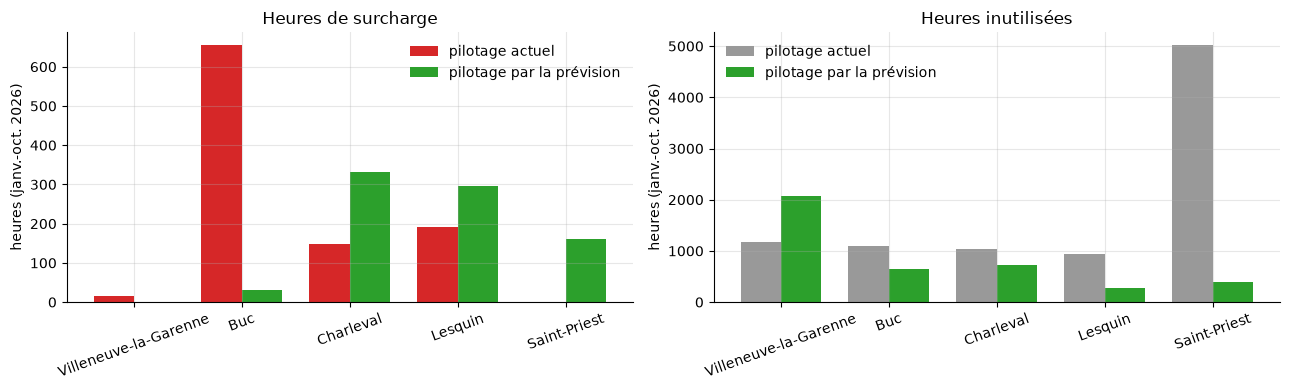

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, couleur in zip(axes, ["heures de surcharge", "heures inutilisées"], ["C3", "0.6"]):
    par_site[col].plot.bar(ax=ax, color=[couleur, "C2"], width=0.75)
    ax.set(title=col.capitalize(), xlabel="", ylabel="heures (janv.-oct. 2026)")
    ax.legend(["pilotage actuel", "pilotage par la prévision"], frameon=False)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

**Comment lire :** à gauche, les heures de surcharge ; à droite, les heures inutilisées. Pour chaque site,
la barre colorée correspond au pilotage actuel, la verte au pilotage par la prévision. On veut des barres
basses des deux côtés.

- À **Buc**, la prévision fait presque disparaître la surcharge de la reprise.
- À **Saint-Priest**, elle supprime l'essentiel du sureffectif.
- À **Charleval** et **Lesquin**, elle fait un peu moins bien sur la surcharge, parce que le modèle
  sous-estime légèrement ces sites. C'est le prix d'un effectif plus serré.
- À **Villeneuve-la-Garenne**, elle ajoute des heures inutilisées : l'arrondi au demi-poste supérieur et la
  cible de 90 % gonflent un peu l'effectif d'un site déjà bien dimensionné.

Au total, sur 5 sites et 10 mois, on paie nettement moins d'heures pour un peu moins de surcharge.

**Mes observations :**
<!-- À compléter : est-ce réaliste d'ajuster l'effectif chaque mois sur un site d'archivage ? -->

## 4. Le plan pour les prochains mois

Maintenant on se place **aujourd'hui** (fin octobre 2026). On entraîne le modèle sur tout l'historique et
on prévoit **novembre 2026 → janvier 2027**, semaine par semaine.

Le modèle a besoin de savoir quels événements sont prévus. Ici, aucun contrat n'est signé dans le dataset
après octobre 2026. **La liste ci-dessous est l'endroit où un responsable d'exploitation renseignerait ses
reprises à venir.** Elle contient un exemple fictif, pour montrer l'effet d'un scénario.

In [7]:
HORIZON_DEBUT, HORIZON_FIN = pd.Timestamp("2026-11-02"), pd.Timestamp("2027-01-31")

# Événements à venir (scénario) : site, début, fin, nombre de boîtes
EVENEMENTS_A_VENIR = [
    ("S04", "2027-01-11", "2027-03-26", 15_000),   # EXEMPLE FICTIF : reprise d'un fonds bancaire à Lesquin
]

# Jours ouvrés futurs : calendrier français
feries = holidays.France(years=[2026, 2027])
futur = pd.DataFrame({"ds": pd.bdate_range(HORIZON_DEBUT, HORIZON_FIN)})
futur = futur[~futur.ds.isin(pd.to_datetime(list(feries.keys())))].reset_index(drop=True)
print(f"{len(futur)} jours ouvrés à prévoir")

62 jours ouvrés à prévoir


In [8]:
# On reprend exactement la préparation du notebook 02
serie    = pd.read_csv(DATA / "prophet_charge_site.csv", parse_dates=["ds"])
dim_evt  = pd.read_csv(DATA / "dim_evenement.csv", parse_dates=["date_debut", "date_fin"])
dim_date = pd.read_csv(DATA / "dim_date.csv", parse_dates=["date"])

# Jours spéciaux passés + à venir (ponts et fin d'année)
tous_jours = pd.DataFrame({"ds": pd.date_range("2021-01-01", "2027-12-31")})
tous_jours["ferie"] = tous_jours.ds.isin(pd.to_datetime(list(holidays.France(years=range(2021, 2028)).keys())))
tous_jours["ouvre"] = (tous_jours.ds.dt.dayofweek < 5) & ~tous_jours.ferie
prec, suiv = tous_jours.ferie.shift(1, fill_value=False), tous_jours.ferie.shift(-1, fill_value=False)
we_prec = tous_jours.ds.shift(1).dt.dayofweek >= 5
we_suiv = tous_jours.ds.shift(-1).dt.dayofweek >= 5
tous_jours["pont"] = tous_jours.ouvre & ((prec & we_suiv) | (suiv & we_prec))
fin_annee = tous_jours[((tous_jours.ds.dt.month == 12) & (tous_jours.ds.dt.day >= 23))
                       | ((tous_jours.ds.dt.month == 1) & (tous_jours.ds.dt.day <= 2))][["ds"]].assign(holiday="fin_annee")
JOURS_SPECIAUX = pd.concat([tous_jours.loc[tous_jours.pont, ["ds"]].assign(holiday="pont"), fin_annee])
jours_ouvres = tous_jours.loc[tous_jours.ouvre, "ds"]

def regresseur(site, dates, avec_scenario):
    evts = dim_evt[(dim_evt.site_id == site) & dim_evt.connu_a_lavance][["date_debut", "date_fin", "nb_boites"]]
    if avec_scenario:
        evts = pd.concat([evts, pd.DataFrame([(pd.Timestamp(a), pd.Timestamp(b), n) for s, a, b, n in EVENEMENTS_A_VENIR
                                              if s == site], columns=evts.columns)])
    r = pd.Series(0.0, index=pd.DatetimeIndex(dates))
    for _, e in evts.iterrows():
        jours = jours_ouvres[jours_ouvres.between(e.date_debut, e.date_fin)]
        r[r.index.isin(jours)] += e.nb_boites / len(jours)
    return (r / 100).values

plan = []
for site in SITES:
    hist = serie[serie.site_id == site][["ds", "y"]].copy()
    hist["evt"] = regresseur(site, hist.ds, avec_scenario=False)
    m = Prophet(growth="flat", holidays=JOURS_SPECIAUX, yearly_seasonality=True, weekly_seasonality=True,
                daily_seasonality=False)
    m.add_regressor("evt")
    m.fit(hist)
    for scenario in [False, True]:
        f = futur.copy()
        f["evt"] = regresseur(site, f.ds, avec_scenario=scenario)
        p = m.predict(f)
        plan.append(pd.DataFrame({"date": f.ds, "site_id": site, "scenario": scenario,
                                  "heures_prevues": p.yhat.clip(lower=0), "borne_haute": p.yhat_upper}))
plan = pd.concat(plan, ignore_index=True)
plan["capacite_1_etp"] = HEURES_JOUR * presence(plan.date.dt.month)

In [9]:
etp_actuels = charge[charge.date == charge.date.max()].set_index("site_id").etp_archivistes

plan_sem = (plan.groupby(["scenario", "site_id", pd.Grouper(key="date", freq="W-MON", label="left", closed="left")])
                .agg(heures_prevues=("heures_prevues", "sum"), borne_haute=("borne_haute", "sum"),
                     capacite_1_etp=("capacite_1_etp", "sum"))
                .reset_index().rename(columns={"date": "semaine_du"}))
plan_sem["etp_necessaires"] = np.ceil(plan_sem.heures_prevues / (plan_sem.capacite_1_etp * TAUX_CIBLE) * 2) / 2
plan_sem["etp_en_place"] = plan_sem.site_id.map(etp_actuels)
plan_sem["ecart_etp"] = plan_sem.etp_necessaires - plan_sem.etp_en_place
plan_sem["statut"] = np.select([plan_sem.ecart_etp >= 0.5, plan_sem.ecart_etp <= -1.5],
                               ["Renfort à prévoir", "Sous-charge : congés / formation"], "OK")

def tableau_plan(scenario):
    t = plan_sem[plan_sem.scenario == scenario].copy()
    t["site"] = t.site_id.map(NOMS)
    return t.pivot(index="semaine_du", columns="site", values="ecart_etp")

def colorer(v):
    if v >= 0.5:  return "background-color: #f4c7c3"
    if v <= -1.5: return "background-color: #d9e7f5"
    return ""

print("Écart entre ETP nécessaires et ETP en place — sans scénario")
print("rouge = renfort à prévoir · bleu = marge pour congés ou formation")
tableau_plan(False).style.format("{:+.1f}").map(colorer)

Écart entre ETP nécessaires et ETP en place — sans scénario
rouge = renfort à prévoir · bleu = marge pour congés ou formation


site,Buc,Charleval,Lesquin,Saint-Priest,Villeneuve-la-Garenne
semaine_du,,,,,
2026-11-02 00:00:00,-1.0,-0.5,-1.5,-3.5,-2.0
2026-11-09 00:00:00,-1.0,-0.5,-1.0,-3.0,-1.5
2026-11-16 00:00:00,-1.0,-0.5,-1.0,-3.0,-1.0
2026-11-23 00:00:00,-1.0,-0.5,-1.0,-3.5,-1.0
2026-11-30 00:00:00,-1.0,+0.0,-1.0,-4.0,-1.0
2026-12-07 00:00:00,-1.0,-0.5,-1.5,-4.0,-1.5
2026-12-14 00:00:00,-0.5,-1.0,-1.5,-4.0,-1.5
2026-12-21 00:00:00,-0.5,-1.5,-2.0,-4.5,-2.5
2026-12-28 00:00:00,-0.5,-1.5,-2.0,-4.5,-3.0


**Comment lire :** une ligne par semaine, une colonne par site. Le chiffre indique combien d'archivistes il
manque (positif) ou il y a en trop (négatif) par rapport à l'équipe actuelle.

- **Rouge** : il manque au moins un demi-poste, il faut prévoir du renfort.
- **Bleu** : au moins 1,5 poste de marge, c'est le bon moment pour poser des congés, lancer un inventaire
  ou une formation.

Ce qui ressort : novembre-décembre est calme partout, avec Saint-Priest toujours en sureffectif d'environ
3,5 postes. En janvier, **Villeneuve-la-Garenne** repasse au-dessus de sa capacité, à cause des
consultations de début d'année des banques et des campagnes de destruction.

C'est **le tableau à envoyer aux responsables de site** chaque mois, mis à jour avec les derniers contrats signés.

In [10]:
print("Même tableau AVEC le scénario fictif (reprise de 15 000 boîtes à Lesquin, de mi-janvier à fin mars)")
tableau_plan(True).style.format("{:+.1f}").map(colorer)

Même tableau AVEC le scénario fictif (reprise de 15 000 boîtes à Lesquin, de mi-janvier à fin mars)


site,Buc,Charleval,Lesquin,Saint-Priest,Villeneuve-la-Garenne
semaine_du,,,,,
2026-11-02 00:00:00,-1.0,-0.5,-1.5,-3.5,-2.0
2026-11-09 00:00:00,-1.0,-0.5,-1.0,-3.0,-1.5
2026-11-16 00:00:00,-1.0,-0.5,-1.0,-3.0,-1.0
2026-11-23 00:00:00,-1.0,-0.5,-1.0,-3.5,-1.0
2026-11-30 00:00:00,-1.0,+0.0,-1.0,-4.0,-1.0
2026-12-07 00:00:00,-1.0,-0.5,-1.5,-4.0,-1.5
2026-12-14 00:00:00,-0.5,-1.0,-1.5,-4.0,-1.5
2026-12-21 00:00:00,-0.5,-1.5,-2.0,-4.5,-2.5
2026-12-28 00:00:00,-0.5,-1.5,-2.0,-4.5,-3.0


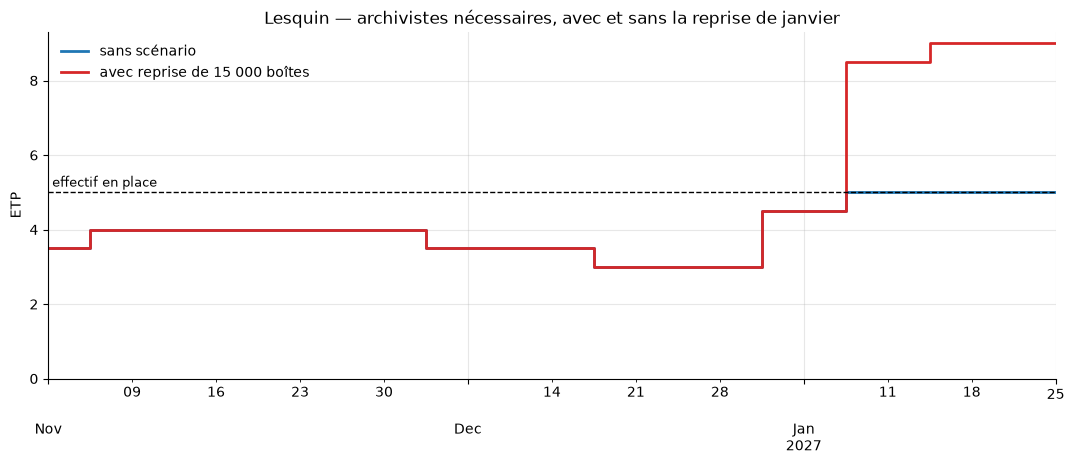

In [11]:
s = plan_sem[plan_sem.site_id == "S04"].pivot(index="semaine_du", columns="scenario", values="etp_necessaires")
ax = s.plot(drawstyle="steps-mid", lw=2, color=["C0", "C3"])
ax.axhline(etp_actuels["S04"], color="k", ls="--", lw=1)
ax.text(s.index[0], etp_actuels["S04"] + 0.15, " effectif en place", fontsize=9)
ax.set(title="Lesquin — archivistes nécessaires, avec et sans la reprise de janvier", ylabel="ETP", xlabel="", ylim=(0, None))
ax.legend(["sans scénario", "avec reprise de 15 000 boîtes"], frameon=False); plt.show()

**Comment lire :** c'est l'usage le plus concret du modèle. Le commercial annonce une reprise ; on la saisit
dans `EVENEMENTS_A_VENIR`, on relance, et on sait combien de personnes il faudra et à partir de quelle
semaine. On a le temps de recruter avant l'arrivée des camions.

Pour tester un autre scénario, modifie la liste en haut de la section 4, puis relance le notebook à partir
de cette cellule.

## 5. Sauvegarder

Ces fichiers peuvent alimenter directement un rapport Power BI.

In [12]:
sem.assign(site=sem.site_id.map(NOMS)).round(2).to_csv(OUT / "effectifs_2026_retrospectif.csv", index=False)
mens.assign(site=mens.site_id.map(NOMS), mois=mens.mois.astype(str)).round(2).to_csv(OUT / "pilotage_mensuel_2026.csv", index=False)
plan_sem.assign(site=plan_sem.site_id.map(NOMS)).round(2).to_csv(OUT / "plan_effectifs_nov2026_janv2027.csv", index=False)
for f in ["effectifs_2026_retrospectif.csv", "pilotage_mensuel_2026.csv", "plan_effectifs_nov2026_janv2027.csv"]:
    print("Écrit :", OUT / f)

Écrit : ..\outputs\effectifs_2026_retrospectif.csv
Écrit : ..\outputs\pilotage_mensuel_2026.csv
Écrit : ..\outputs\plan_effectifs_nov2026_janv2027.csv


## 6. Ce qu'on retient

<!-- À rédiger avec tes mots. Pistes :
- le pilotage actuel se trompe dans les deux sens (Buc en manque, Saint-Priest en trop) ;
- ce que la prévision change, en heures et en ETP ;
- le réglage des alertes est une décision métier : qui la prendrait chez un archiveur ?
- les limites : ajuster un effectif chaque mois n'est pas gratuit (recrutement, formation d'un intérimaire),
  et le modèle sous-estime légèrement certains sites.
-->